# 05 · Modelos de difusión: cómo se generan hoy las imágenes

Todos los generadores de imágenes de los últimos años (los que convierten una frase en una imagen) son, en el fondo, una red entrenada para hacer algo casi absurdamente simple: **mirar una imagen ruidosa y adivinar el ruido**. Si repites esa adivinanza en bucle, empezando por pura estática, aparece una imagen.

En este notebook construimos toda la idea desde cero en PyTorch, con los dígitos manuscritos de 8×8 que trae scikit-learn, de modo que cada experimento corre en la CPU de un portátil. Después medimos qué aportan realmente los trucos de muestreo (DDIM, guía), movemos la difusión al espacio latente de un autoencoder y terminamos viendo cómo se ensambla un sistema de texto a imagen a partir de estas piezas.

**Se apoya en** (sitio del curso: [neural-networks.academy.forwardforecasting.eu](https://neural-networks.academy.forwardforecasting.eu/es/))

| Notebook | Qué reutilizamos |
|---|---|
| 01 neurona, 02 retropropagación, 03 entrenar bien | descenso del gradiente, curvas de pérdida, por qué importan los calendarios de tasa de aprendizaje y la normalización |
| 05 redes convolucionales | los bloques convolucionales de nuestro eliminador de ruido |
| 08 transformer | la atención, que es como los sistemas reales leen el prompt de texto (sección 7) |
| 11 visión más allá de la clasificación | la U-Net (un codificador-decodificador con conexiones de salto) |

¿Nuevo en PyTorch? El [capítulo de frameworks de IA de Python 1001](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) cubre tensores, módulos y bucles de entrenamiento.

**Contenido**
1. El problema de la generación, y por qué los VAE y las GAN eran difíciles
2. El proceso directo: destruir una imagen con ruido (forma cerrada, calendario lineal frente a coseno)
3. El eliminador de ruido: una U-Net pequeña con embeddings de paso temporal y de clase, y la pérdida de entrenamiento
4. Muestreo: DDPM (modelo probabilístico de difusión con eliminación de ruido) y el más rápido DDIM (modelo implícito), medidos
5. Generación condicionada por clase y guía sin clasificador, medidas
6. Difusión latente: difusión en el espacio latente de un autoencoder
7. Cómo encaja un sistema de texto a imagen (diagrama, tabla y un modelo preentrenado pequeño)
8. Qué le falta a este juguete, y seguridad y ética
9. Ideas clave, ejercicios, referencias

Tiempo de ejecución: unos 3 minutos en un entorno limpio de 2 CPU, con la demo opcional con un modelo preentrenado de la sección 7 incluida (modelos ya en caché; la primera vez se descargan unos 1,1 GB).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/05_modelos_de_difusion.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 3 minutos, con un pico de memoria de unos 3,3 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'diffusers': 'diffusers',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, os
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits

torch.set_num_threads(2); torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())
def show(ax, img, title=None):
    ax.imshow(img.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1, interpolation="nearest"); ax.axis("off")
    if title: ax.set_title(title, fontsize=8)

## 1. El problema de la generación, y por qué los VAE y las GAN eran difíciles

Un **modelo generativo** aprende la distribución $p(x)$ de unos datos (aquí, imágenes de dígitos) lo bastante bien como para extraer muestras nuevas de ella. Los datos de entrenamiento son solo ejemplos, así que el modelo debe convertir "un montón de ejemplos" en "una máquina que fabrica más".

Antes de la difusión dominaban dos familias:

| Familia | Idea | Por qué era difícil |
|---|---|---|
| **VAE** (autoencoder variacional, [Kingma y Welling](https://arxiv.org/abs/1312.6114), 2014) | codificar a un vector latente pequeño, decodificar de vuelta y empujar la distribución latente hacia una gaussiana simple | estable y fácil de entrenar, pero la pérdida de reconstrucción píxel a píxel promedia entre salidas plausibles, así que las muestras salen **borrosas** |
| **GAN** (red generativa antagónica, [Goodfellow et al.](https://arxiv.org/abs/1406.2661), 2014) | un generador intenta engañar a un discriminador que intenta detectar falsificaciones | muestras nítidas, pero el entrenamiento es un **juego de dos jugadores**: puede oscilar, colapsar en pocas salidas (**colapso de modos**) o atascarse, y exige mucho ajuste |
| **Difusión** (Sohl-Dickstein et al., [2015](https://arxiv.org/abs/1503.03585); [Ho et al.](https://arxiv.org/abs/2006.11239), 2020) | aprender a deshacer un proceso gradual de adición de ruido, un paso pequeño cada vez | el entrenamiento es una simple regresión con una **única pérdida estable**, cubre todos los modos de los datos; el precio es un **muestreo lento** (muchas evaluaciones de la red por imagen) |

El trato de la difusión es: sustituir un problema difícil (producir una imagen entera de un golpe) por muchos fáciles (quitar un poco de ruido a una imagen). El resto del notebook es ese trato, medido.

**Datos.** `sklearn.datasets.load_digits`: 1797 imágenes en escala de grises de 8×8 de dígitos manuscritos, una copia del conjunto de test de "Optical Recognition of Handwritten Digits" de UCI ([Alpaydin y Kaynak](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits), licencia CC BY 4.0), incluida en scikit-learn, así que no se descarga nada. Reescalamos los píxeles de 0..16 a $[-1, 1]$ (la convención de los modelos de difusión) y guardamos 1400 imágenes para entrenar y 397 para probar.

**Juzgar imágenes generadas.** Un generador no tiene "exactitud", así que usamos dos medidas, ambas con un **clasificador independiente** entrenado solo con las imágenes reales de entrenamiento (una CNN pequeña que los modelos generativos nunca usan):

* **exactitud de clase**: cuando pedimos un "7", ¿el clasificador independiente dice "7"? Mide si las muestras son reconocibles y aciertan el objetivo;
* **distancia de Fréchet (FD)** entre las características ocultas del clasificador para imágenes generadas y para imágenes reales de test. Es la misma idea que la conocida FID (distancia de Fréchet de Inception) pero con nuestro clasificador pequeño en lugar de Inception. Menor es mejor; mide cuánto se parece la distribución *completa* generada a la real.

Como suelo de referencia calculamos también la FD entre las imágenes reales de *entrenamiento* y las de *test*: no cabe esperar que ningún generador la supere.

In [2]:
d = load_digits()
X_all = torch.tensor(d.images / 16 * 2 - 1, dtype=torch.float32).unsqueeze(1)      # (1797, 1, 8, 8) en [-1, 1]
y_all = torch.tensor(d.target)
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(0))
X_all, y_all = X_all[perm], y_all[perm]
Xtr, ytr, Xte, yte = X_all[:1400], y_all[:1400], X_all[1400:], y_all[1400:]
print("entrenamiento", tuple(Xtr.shape), "prueba", tuple(Xte.shape))

class Judge(nn.Module):
    # clasificador independiente; su capa oculta es el espacio de características para la distancia de Frechet
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                               nn.MaxPool2d(2), nn.Flatten(), nn.Linear(32 * 16, 32), nn.ReLU())
        self.o = nn.Linear(32, 10)
    def forward(self, x): return self.o(self.f(x))

judge = Judge(); opt = torch.optim.Adam(judge.parameters(), 2e-3)
for ep in range(25):
    p = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 64):
        b = p[i:i + 64]; loss = F.cross_entropy(judge(Xtr[b]), ytr[b]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()
for q in judge.parameters(): q.requires_grad_(False)
print(f"clasificador independiente, exactitud en imágenes reales de prueba: {(judge(Xte).argmax(1) == yte).float().mean():.1%}")

def feats(x): return judge.f(x).numpy().astype(np.float64)
def frechet(fa, fb, eps=1e-6):
    m1, m2 = fa.mean(0), fb.mean(0)
    c1 = np.cov(fa.T) + eps * np.eye(fa.shape[1]); c2 = np.cov(fb.T) + eps * np.eye(fb.shape[1])
    s = scipy.linalg.sqrtm(c1 @ c2).real
    return float(((m1 - m2) ** 2).sum() + np.trace(c1 + c2 - 2 * s))

F_REAL = feats(Xte)
def diversity(x, c):
    # distancia media entre pares de imágenes de la MISMA clase (mayor = más variado)
    return float(np.mean([torch.pdist(x[c == k].flatten(1)).mean().item() for k in range(10) if (c == k).sum() > 1]))

def evaluate(x, c):
    return dict(acc=(judge(x).argmax(1) == c).float().mean().item(), fd=frechet(feats(x), F_REAL), div=diversity(x, c))

floor = evaluate(Xtr[:397], ytr[:397])
noise = evaluate(torch.randn(397, 1, 8, 8).clamp(-1, 1), yte)
print(f"referencia: real entrenamiento vs real prueba   FD = {frechet(feats(Xtr), F_REAL):.2f}   diversidad = {diversity(Xte, yte):.2f}")
print(f"referencia: ruido puro                      FD = {noise['fd']:.2f}   exactitud de clase = {noise['acc']:.1%}")

entrenamiento (1400, 1, 8, 8) prueba (397, 1, 8, 8)


clasificador independiente, exactitud en imágenes reales de prueba: 97.7%


referencia: real entrenamiento vs real prueba   FD = 5.56   diversidad = 4.53
referencia: ruido puro                      FD = 630.26   exactitud de clase = 10.3%


## 2. El proceso directo: destruir una imagen con ruido

Toma una imagen limpia $x_0$ (el subíndice es el **paso temporal** $t$; $t=0$ es limpia). El **proceso directo** añade un poco de ruido gaussiano en cada uno de $T$ pasos:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\big(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big),$$

donde $\beta_t \in (0,1)$ es el **nivel de ruido** del paso $t$ (el "calendario") y $\mathcal{N}(\mu, \sigma^2)$ es una gaussiana de media $\mu$ y varianza $\sigma^2$. Como una suma de gaussianas es gaussiana, no hace falta iterar: definimos $\alpha_t = 1-\beta_t$ y $\bar\alpha_t = \prod_{s \le t}\alpha_s$ (la señal acumulada que sobrevive). Entonces podemos saltar directamente a cualquier paso:

$$\boxed{q(x_t \mid x_0) = \mathcal{N}\big(x_t;\ \sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t) I\big)} \qquad\Longleftrightarrow\qquad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\quad \varepsilon \sim \mathcal{N}(0, I).$$

Así, $x_t$ es una **mezcla de imagen y ruido**: en $t=0$, $\bar\alpha \approx 1$ (todo imagen); en $t=T$, $\bar\alpha \approx 0$ (todo ruido). Esta forma cerrada es lo que abarata el entrenamiento: para entrenar en el paso $t$ saltamos allí directamente en una línea.

**El calendario** decide con qué rapidez pasamos de imagen a ruido. El calendario **lineal** original (Ho et al. 2020) sube $\beta_t$ linealmente (reescalamos sus valores habituales de 1000 pasos a nuestros $T=100$ pasos). [Nichol y Dhariwal](https://arxiv.org/abs/2102.09672) (2021) notaron que destruye la imagen demasiado pronto, desperdiciando muchos pasos en ruido puro, y propusieron el calendario **coseno**, $\bar\alpha_t \propto \cos^2\!\big(\tfrac{t/T + s}{1+s}\tfrac{\pi}{2}\big)$ con un pequeño desplazamiento $s$, que mantiene la información viva más tiempo. La **relación señal-ruido** $\mathrm{SNR}(t) = \bar\alpha_t / (1-\bar\alpha_t)$ lo resume.

tras 50 pasos reales de ruido : media 0.492, desv. 0.712
forma cerrada q(x_t | x_0)    : media 0.492, desv. 0.711


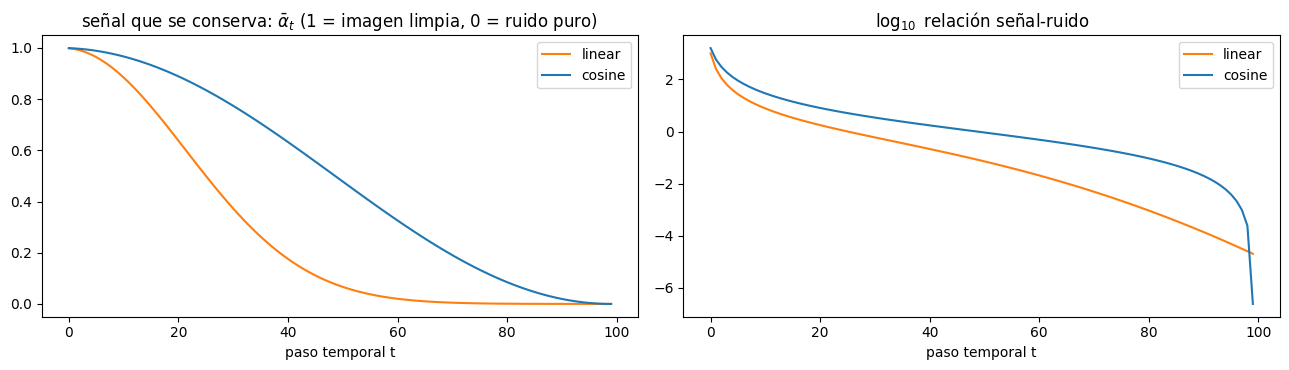

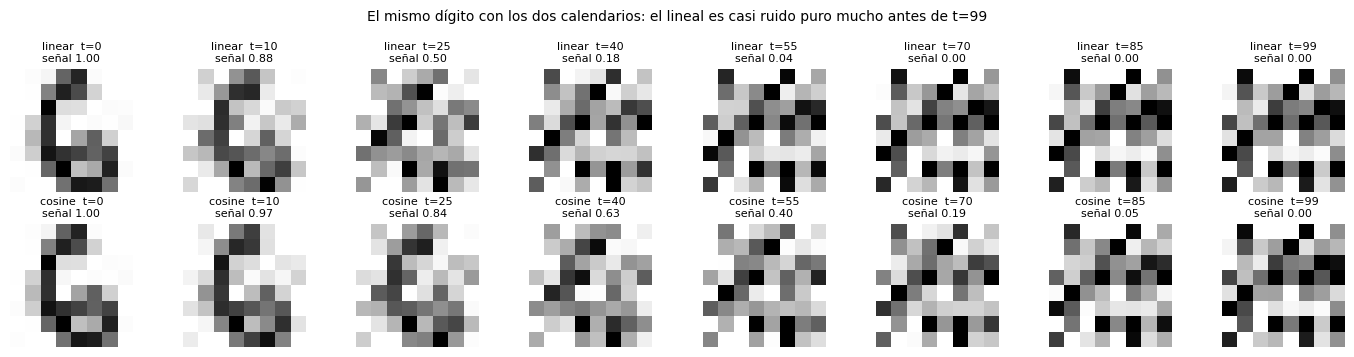

fracción de pasos en los que queda menos del 5% de la varianza de la señal: {'linear': '47%', 'cosine': '15%'}


In [3]:
T = 100                                                         # número de pasos de difusión (los sistemas reales usan 1000)

def make_schedule(kind):
    if kind == "linear":                                        # Ho et al. 2020: beta de 1e-4 a 0.02 en 1000 pasos, reescalado a T pasos
        betas = torch.linspace(1e-4 * 1000 / T, 0.02 * 1000 / T, T)
    else:                                                       # Nichol y Dhariwal 2021
        s = 0.008; t = torch.arange(T + 1) / T
        f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
        betas = (1 - f[1:] / f[:-1]).clamp(max=0.999)
    return betas, torch.cumprod(1 - betas, 0)

SCH = {k: make_schedule(k) for k in ["linear", "cosine"]}

# 1) comprobar la forma cerrada frente a ejecutar de verdad los pasos de ruido uno a uno
betas, ab = SCH["cosine"]
g = torch.Generator().manual_seed(1)
x = torch.full((200000,), 0.7)                                  # 200000 copias de un píxel con valor 0.7
for t in range(50):
    x = (1 - betas[t]).sqrt() * x + betas[t].sqrt() * torch.randn(x.shape, generator=g)
print(f"tras 50 pasos reales de ruido : media {x.mean():.3f}, desv. {x.std():.3f}")
print(f"forma cerrada q(x_t | x_0)    : media {(ab[49].sqrt() * 0.7):.3f}, desv. {(1 - ab[49]).sqrt():.3f}")

# 2) los dos calendarios
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, col in [("linear", "tab:orange"), ("cosine", "tab:blue")]:
    ab_k = SCH[k][1]
    axes[0].plot(ab_k, color=col, label=k)
    axes[1].plot(torch.log10(ab_k / (1 - ab_k)), color=col, label=k)
axes[0].set_title(r"señal que se conserva: $\bar\alpha_t$ (1 = imagen limpia, 0 = ruido puro)"); axes[0].set_xlabel("paso temporal t"); axes[0].legend()
axes[1].set_title(r"$\log_{10}$ relación señal-ruido"); axes[1].set_xlabel("paso temporal t"); axes[1].legend()
plt.tight_layout(); plt.show()

# 3) imágenes disolviéndose en ruido
x0 = Xtr[0:1]; eps = torch.randn(1, 1, 8, 8, generator=torch.Generator().manual_seed(2))
ts = [0, 10, 25, 40, 55, 70, 85, 99]
fig, axes = plt.subplots(2, len(ts), figsize=(14, 3.6))
for r, k in enumerate(["linear", "cosine"]):
    for j, t in enumerate(ts):
        a = SCH[k][1][t]
        show(axes[r, j], (a.sqrt() * x0 + (1 - a).sqrt() * eps), f"{k}  t={t}\nseñal {a:.2f}")
plt.suptitle("El mismo dígito con los dos calendarios: el lineal es casi ruido puro mucho antes de t=99", fontsize=10)
plt.tight_layout(); plt.show()
print("fracción de pasos en los que queda menos del 5% de la varianza de la señal:",
      {k: f"{(SCH[k][1] < 0.05).float().mean():.0%}" for k in SCH})

**Lectura.** La forma cerrada no es una aproximación: tras 50 pasos reales de ruido, los píxeles simulados tienen media 0,492 y desviación típica 0,712, frente a 0,492 y 0,711 de la fórmula. Los calendarios difieren mucho. Con el lineal, el 47 % de los 100 pasos temporales tiene menos del 5 % de la varianza de la señal (la fila inferior de imágenes ya es pura estática desde aproximadamente t=55), así que casi la mitad del trabajo de eliminación de ruido se gastaría en ruido sin información. El calendario coseno deja solo el 15 % de los pasos en ese régimen y reparte la disolución de forma uniforme. Ese es todo el argumento de Nichol y Dhariwal a favor del coseno, y por eso entrenamos con él. (No entrenamos un modelo con calendario lineal para medir la diferencia en la calidad de las muestras; es el ejercicio 1.)

## 3. El eliminador de ruido: una U-Net pequeña y la pérdida de entrenamiento

Invertir el proceso significa estimar $p(x_{t-1} \mid x_t)$. Ho et al. mostraron que, con pasos pequeños, este paso inverso también es gaussiano y que su media se calcula a partir de una sola cosa: **el ruido $\varepsilon$ que se mezcló en $x_t$**. Así que entrenamos una red $\varepsilon_\theta(x_t, t)$ ($\theta$ = sus pesos) con la pérdida más simple posible:

$$L = \mathbb{E}_{x_0,\ t,\ \varepsilon}\ \big\|\ \varepsilon - \varepsilon_\theta\big(\sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\ t\big)\big\|^2 .$$

Un paso de entrenamiento: elegir una imagen, un $t$ aleatorio y un ruido $\varepsilon$ aleatorio, construir $x_t$ con la forma cerrada y pedirle a la red $\varepsilon$. Eso es todo.

**La visión de *score matching*, en un párrafo.** El *score* de una distribución es $\nabla_x \log p(x)$, la dirección en la que una imagen se vuelve más probable. Para la imagen ruidosa, $\nabla_{x_t}\log q(x_t \mid x_0) = -\varepsilon/\sqrt{1-\bar\alpha_t}$, así que predecir el ruido equivale a estimar el score de los datos ruidosos (*denoising score matching*), salvo una escala conocida. Muestrear consiste entonces en subir por la densidad de los datos paso a paso, con algo de aleatoriedad inyectada: una versión discretizada de la dinámica de Langevin o, en la visión en tiempo continuo de [Song et al. (2021)](https://arxiv.org/abs/2011.13456), el inverso de una ecuación diferencial estocástica. El mismo modelo con tres vocabularios.

**La red.** Debe saber *cuánto ruido* tiene su entrada, así que le damos el paso temporal $t$ mediante un **embedding sinusoidal** (la misma idea que la codificación posicional del notebook 09 de Redes Neuronales 1001), pasado por un pequeño MLP y **sumado dentro de cada bloque**. También le damos un **embedding de clase** (etiqueta del dígito 0-9, más un token especial "sin etiqueta" 10). Durante el entrenamiento la etiqueta se sustituye por ese token el 15 % de las veces; la sección 5 explica por qué. La arquitectura es una U-Net (notebook 11 de Redes Neuronales 1001) con dos niveles de resolución (8×8 y 4×4) y un cuello de botella de 2×2.

Parámetros de la U-Net: 150,529


entrenados 1500 pasos en 284s, pérdida final 0.132


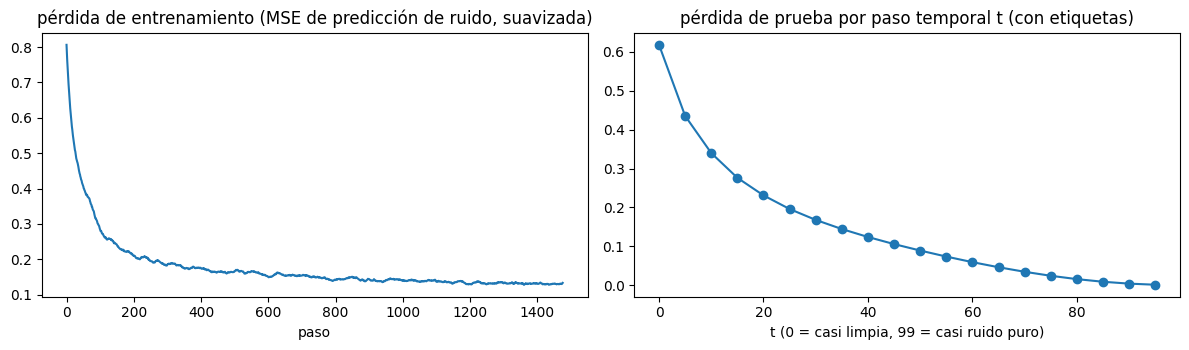

In [4]:
class Block(nn.Module):
    # bloque convolucional cuyas activaciones se desplazan con el embedding (paso temporal + clase)
    def __init__(self, cin, cout, emb):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1); self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.n1 = nn.GroupNorm(4, cout); self.n2 = nn.GroupNorm(4, cout)
        self.e = nn.Linear(emb, cout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = F.silu(self.n1(self.c1(x))) + self.e(e)[:, :, None, None]
        h = F.silu(self.n2(self.c2(h)))
        return h + self.skip(x)

def timestep_embedding(t, dim):
    # embedding sinusoidal del paso temporal entero, como la codificación posicional del transformer
    freqs = torch.exp(-math.log(1000) * torch.arange(dim // 2) / (dim // 2))
    a = t[:, None].float() * freqs[None]
    return torch.cat([a.sin(), a.cos()], 1)

class UNet(nn.Module):
    def __init__(self, ch=24, emb=64):
        super().__init__()
        self.emb = emb
        self.t_mlp = nn.Sequential(nn.Linear(emb, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.cls = nn.Embedding(11, emb)                         # dígitos 0-9, y 10 = "sin etiqueta"
        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        self.d1 = Block(ch, ch, emb)                             # 8x8
        self.d2 = Block(ch, 2 * ch, emb)                         # 4x4
        self.mid = Block(2 * ch, 2 * ch, emb)                    # 2x2
        self.u2 = Block(4 * ch, ch, emb)                         # de vuelta a 4x4, con salto desde d2
        self.u1 = Block(2 * ch, ch, emb)                         # de vuelta a 8x8, con salto desde d1
        self.out = nn.Conv2d(ch, 1, 3, padding=1)
    def forward(self, x, t, c):
        e = self.t_mlp(timestep_embedding(t, self.emb)) + self.cls(c)
        h0 = self.d1(self.inp(x), e)
        h1 = self.d2(F.avg_pool2d(h0, 2), e)
        m = self.mid(F.avg_pool2d(h1, 2), e)
        u = self.u2(torch.cat([F.interpolate(m, scale_factor=2), h1], 1), e)
        u = self.u1(torch.cat([F.interpolate(u, scale_factor=2), h0], 1), e)
        return self.out(u)

NULL = 10
betas, ab = SCH["cosine"]
unet = UNet()
print(f"Parámetros de la U-Net: {count_params(unet):,}")

STEPS, BS, P_DROP = 1500, 128, 0.15
opt = torch.optim.AdamW(unet.parameters(), 2e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=STEPS)
gen = torch.Generator().manual_seed(0)
losses, t0 = [], time.time()
for it in range(STEPS):
    b = torch.randint(0, len(Xtr), (BS,), generator=gen)
    x0, c = Xtr[b], ytr[b].clone()
    c[torch.rand(BS, generator=gen) < P_DROP] = NULL             # eliminación de etiquetas, para la guía sin clasificador
    t = torch.randint(0, T, (BS,), generator=gen)
    eps = torch.randn(x0.shape, generator=gen)
    a = ab[t][:, None, None, None]
    xt = a.sqrt() * x0 + (1 - a).sqrt() * eps                    # proceso directo en forma cerrada
    loss = F.mse_loss(unet(xt, t, c), eps)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    losses.append(loss.item())
unet.eval()
print(f"entrenados {STEPS} pasos en {time.time() - t0:.0f}s, pérdida final {np.mean(losses[-50:]):.3f}")

# cómo es la pérdida por paso temporal (con imágenes de prueba)
with torch.no_grad():
    per_t = []
    for t_ in range(0, T, 5):
        tt = torch.full((len(Xte),), t_); e_ = torch.randn(Xte.shape, generator=torch.Generator().manual_seed(3))
        a_ = ab[t_]; xt_ = a_.sqrt() * Xte + (1 - a_).sqrt() * e_
        per_t.append(F.mse_loss(unet(xt_, tt, yte), e_).item())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(np.convolve(losses, np.ones(25) / 25, mode="valid")); axes[0].set_title("pérdida de entrenamiento (MSE de predicción de ruido, suavizada)"); axes[0].set_xlabel("paso")
axes[1].plot(range(0, T, 5), per_t, "o-"); axes[1].set_title("pérdida de prueba por paso temporal t (con etiquetas)"); axes[1].set_xlabel("t (0 = casi limpia, 99 = casi ruido puro)")
plt.tight_layout(); plt.show()

**Lectura.** La red tiene 150 529 parámetros y se entrena en unos 1500 pasos; la pérdida baja de alrededor de 1 (predecir ruido cero) a 0,13. La gráfica de la derecha es la interesante: el error es **máximo con $t$ pequeño** (unos 0,6) y casi cero con $t$ grande. Es natural. Cuando la imagen es casi ruido puro, el ruido es la entrada, así que adivinarlo es fácil; cuando la imagen está casi limpia, el ruido es diminuto y difícil de distinguir del detalle fino real del dígito. Por tanto las decisiones más difíciles de la generación son los últimos pasos, donde se deciden los detalles. (El tiempo absoluto impreso arriba depende de la máquina; en un portátil ocupado puede ser varias veces mayor que en uno libre.)

## 4. Muestreo: DDPM y el más rápido DDIM

**Muestreo ancestral (DDPM).** Se parte de ruido puro $x_T \sim \mathcal{N}(0, I)$ y se repite para $t = T, \dots, 1$: pedir a la red $\hat\varepsilon$, estimar la imagen limpia $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$, calcular la media de la gaussiana $q(x_{t-1}\mid x_t, \hat x_0)$ y **añadir ruido nuevo** de varianza $\tilde\beta_t = \beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$. Requiere una llamada a la red por paso de entrenamiento, es decir, $T$ llamadas.

**DDIM** ([Song, Meng y Ermon, 2021](https://arxiv.org/abs/2010.02502)) observó que la *misma red entrenada* admite una familia de muestreadores, incluido uno **determinista** ($\eta = 0$, donde $\eta$ es la cantidad de ruido nuevo inyectado) que además puede **saltarse pasos**: se elige una subsecuencia de pasos temporales, por ejemplo uno de cada 5, y se salta entre ellos:

$$x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t'}-\sigma^2}\,\hat\varepsilon + \sigma\,z,\qquad \sigma = \eta\sqrt{\tfrac{1-\bar\alpha_{t'}}{1-\bar\alpha_t}\big(1-\tfrac{\bar\alpha_t}{\bar\alpha_{t'}}\big)},$$

con $t'$ el siguiente paso (anterior) de la subsecuencia y $z\sim\mathcal{N}(0,I)$. Con $\eta=1$ y todos los pasos es exactamente DDPM; con $\eta=0$ la correspondencia ruido $\to$ imagen es determinista, lo que además permite interpolar entre imágenes en el espacio del ruido.

Abajo, el muestreador se escribe una sola vez y se usa en todos los experimentos. $w$ es la escala de guía de la sección 5 (0 = modelo condicional simple). Generamos 300 dígitos (30 por clase, con el mismo ruido inicial para todos los muestreadores para que la comparación sea justa) y los puntuamos con el clasificador independiente.

muestreador  pasos  exactitud      FD diversidad segundos
DDPM           100      97.0%    8.32       4.21     13.8
DDIM eta=0       5      99.3%   20.40       3.47      0.7
DDIM eta=0      10      97.7%   14.21       3.97      1.4
DDIM eta=0      20      96.0%   13.70       4.20      2.8
DDIM eta=0      50      95.0%   16.56       4.33      6.6
DDIM eta=0     100      94.3%   23.19       4.42     13.3
DDIM eta=1      10      99.3%   13.80       3.58      1.3
DDIM eta=1      20      99.3%    8.24       3.89      2.7
real prueba      -          -    5.56       4.53   (FD: entrenamiento vs prueba)


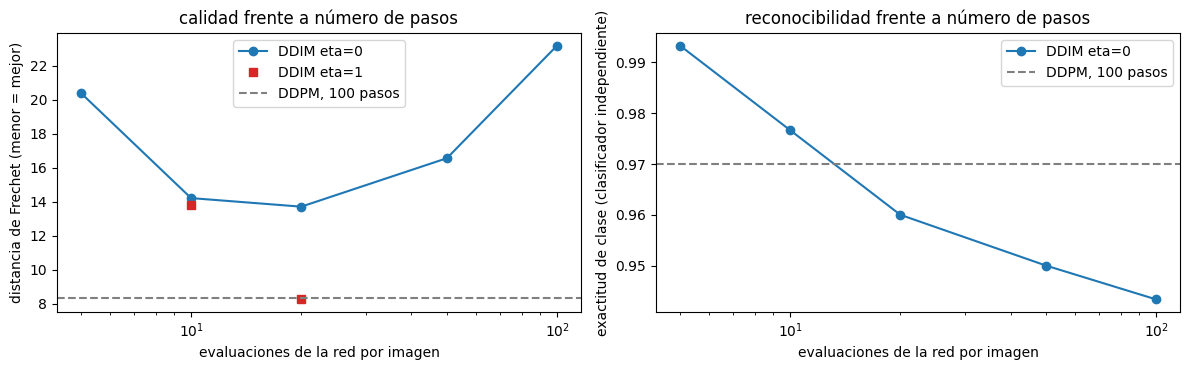

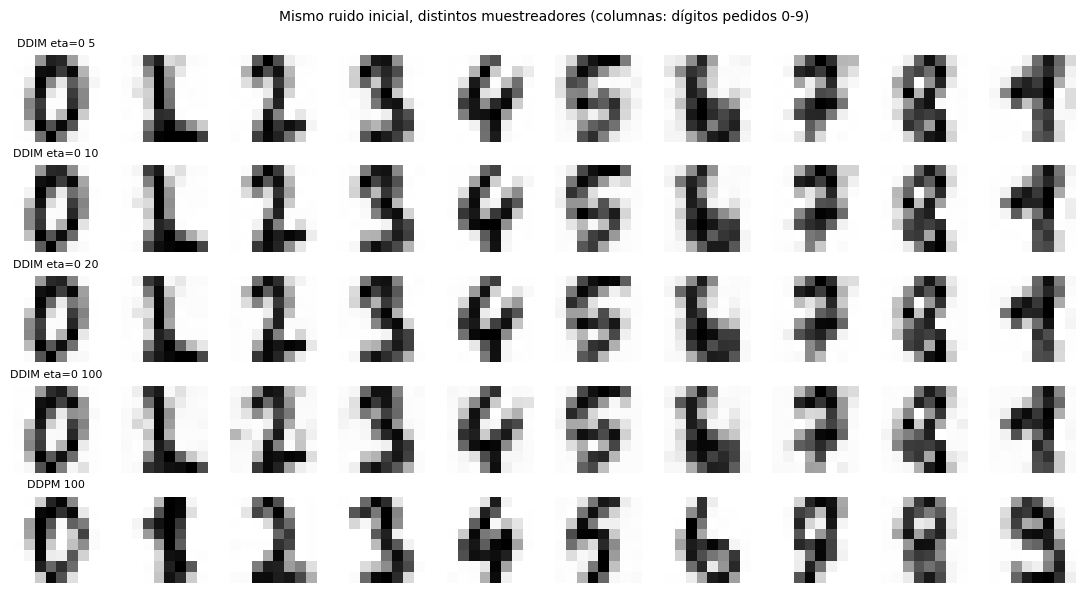

In [5]:
@torch.no_grad()
def eps_hat(net, x, t, c, w):
    tt = torch.full((len(x),), int(t))
    e_c = net(x, tt, c)
    if w == 0: return e_c
    e_u = net(x, tt, torch.full_like(c, NULL))                   # la misma red, con la etiqueta oculta
    return (1 + w) * e_c - w * e_u                               # guía sin clasificador (Ho y Salimans 2022)

@torch.no_grad()
def ddpm_sample(net, shape, c, w=0.0, seed=0):
    # muestreo ancestral: T llamadas a la red, ruido nuevo en cada paso
    g = torch.Generator().manual_seed(seed); x = torch.randn(shape, generator=g)
    for t in range(T - 1, -1, -1):
        e = eps_hat(net, x, t, c, w)
        a, ap = ab[t], (ab[t - 1] if t > 0 else torch.tensor(1.0))
        x0 = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        mean = (ap.sqrt() * betas[t] / (1 - a)) * x0 + ((1 - betas[t]).sqrt() * (1 - ap) / (1 - a)) * x
        var = betas[t] * (1 - ap) / (1 - a)
        x = mean + (var.sqrt() * torch.randn(shape, generator=g) if t > 0 else 0)
    return x.clamp(-1, 1)

@torch.no_grad()
def ddim_sample(net, shape, c, w=0.0, steps=20, eta=0.0, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.randn(shape, generator=g)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, t in enumerate(ts):
        e = eps_hat(net, x, t, c, w)
        a = ab[t]; ap = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        sigma = eta * ((1 - ap) / (1 - a) * (1 - a / ap)).sqrt()
        x = ap.sqrt() * x0 + (1 - ap - sigma ** 2).clamp(min=0).sqrt() * e + sigma * torch.randn(shape, generator=g)
    return x.clamp(-1, 1)

N = 300
c_eval = torch.arange(N) % 10
runs = [("DDPM", T, None)] + [(f"DDIM eta=0", s, 0.0) for s in (5, 10, 20, 50, 100)] + [("DDIM eta=1", s, 1.0) for s in (10, 20)]
results, samples = [], {}
for name, steps, eta in runs:
    t0 = time.time()
    xs = ddpm_sample(unet, (N, 1, 8, 8), c_eval) if name == "DDPM" else ddim_sample(unet, (N, 1, 8, 8), c_eval, steps=steps, eta=eta)
    dt = time.time() - t0
    r = evaluate(xs, c_eval); r.update(name=name, steps=steps, secs=dt); results.append(r); samples[(name, steps)] = xs
print(f"{'muestreador':12s} {'pasos':>5s} {'exactitud':>10s} {'FD':>7s} {'diversidad':>10s} {'segundos':>8s}")
for r in results:
    print(f"{r['name']:12s} {r['steps']:5d} {r['acc']:10.1%} {r['fd']:7.2f} {r['div']:10.2f} {r['secs']:8.1f}")
print(f"{'real prueba':12s} {'-':>5s} {'-':>10s} {frechet(feats(Xtr), F_REAL):7.2f} {diversity(Xte, yte):10.2f}   (FD: entrenamiento vs prueba)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
dd = [r for r in results if r["name"] == "DDIM eta=0"]
axes[0].plot([r["steps"] for r in dd], [r["fd"] for r in dd], "o-", label="DDIM eta=0")
for r in results:
    if r["name"] == "DDIM eta=1": axes[0].plot(r["steps"], r["fd"], "s", color="tab:red", label="DDIM eta=1" if r["steps"] == 10 else None)
axes[0].axhline(results[0]["fd"], color="gray", ls="--", label="DDPM, 100 pasos")
axes[0].set_xscale("log"); axes[0].set_xlabel("evaluaciones de la red por imagen"); axes[0].set_ylabel("distancia de Frechet (menor = mejor)"); axes[0].legend(); axes[0].set_title("calidad frente a número de pasos")
axes[1].plot([r["steps"] for r in dd], [r["acc"] for r in dd], "o-", label="DDIM eta=0")
axes[1].axhline(results[0]["acc"], color="gray", ls="--", label="DDPM, 100 pasos")
axes[1].set_xscale("log"); axes[1].set_xlabel("evaluaciones de la red por imagen"); axes[1].set_ylabel("exactitud de clase (clasificador independiente)"); axes[1].legend(); axes[1].set_title("reconocibilidad frente a número de pasos")
plt.tight_layout(); plt.show()

rows = [("DDIM eta=0", 5), ("DDIM eta=0", 10), ("DDIM eta=0", 20), ("DDIM eta=0", 100), ("DDPM", T)]
fig, axes = plt.subplots(len(rows), 10, figsize=(11, 1.2 * len(rows)))
for r, key in enumerate(rows):
    for k in range(10):
        show(axes[r, k], samples[key][k], f"{key[0]} {key[1]}" if k == 0 else None)
plt.suptitle("Mismo ruido inicial, distintos muestreadores (columnas: dígitos pedidos 0-9)", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** Destacan tres cosas. (1) El **DDPM ancestral con 100 pasos** es el mejor en calidad de distribución: FD 8,3 (el suelo entre imágenes reales de entrenamiento y de prueba es 5,6), el 97,0 % de las muestras reconocidas como el dígito pedido, diversidad 4,21 frente a 4,53 de los datos reales. (2) **DDIM con eta=1 y 20 pasos** alcanza la misma FD (8,2) con una quinta parte de las llamadas a la red: la aceleración es real. (3) El DDIM **determinista** (eta=0) sorprende más: va bien con 10 a 20 pasos (FD 14,2 y 13,7), claramente peor con 5 pasos (FD 20,4; las imágenes son suaves y menos variadas, diversidad 3,47) y **también empeora con más pasos** (FD 23,2 con 100 pasos, determinista pero no mejor que la ejecución de 20 pasos). La teoría dice que más pasos deberían converger a la misma respuesta; lo que medimos es el comportamiento de una red imperfecta, cuyos pequeños errores se acumulan a lo largo de un camino determinista mientras que el ruido nuevo del muestreo ancestral los va corrigiendo. Es una red y una semilla, con 300 muestras por fila, así que diferencias de pocos puntos de FD están dentro del ruido; el orden "DDPM y eta=1 mejor que eta=0" es lo bastante grande como para fiarse, la curva exacta de eta=0 no. La exactitud de clase apenas separa los muestreadores (94 a 99 % en todos), por eso medimos también la FD y la diversidad: el clasificador solo dice si un dígito es reconocible, no si la *distribución* es correcta.

## 5. Generación condicionada por clase y guía sin clasificador

Nuestra red ya recibe la etiqueta del dígito, así que podemos pedir un "7". Sin embargo, un modelo condicional suele producir imágenes que solo están *vagamente* ligadas a la etiqueta. La **guía sin clasificador** (*classifier-free guidance*, [Ho y Salimans, 2022](https://arxiv.org/abs/2207.12598)) refuerza ese vínculo con un truco y sin red adicional. Durante el entrenamiento la etiqueta se oculta a veces (usamos el token "sin etiqueta" el 15 % de las veces), de modo que **una sola red aprende ambas** estimaciones de ruido, la condicional $\varepsilon_\theta(x_t, t, c)$ y la incondicional $\varepsilon_\theta(x_t, t, \varnothing)$. Al muestrear extrapolamos alejándonos de la incondicional:

$$\tilde\varepsilon = (1+w)\,\varepsilon_\theta(x_t, t, c) - w\,\varepsilon_\theta(x_t, t, \varnothing),$$

donde $w \ge 0$ es la **escala de guía** (el símbolo $c$ es la clase y $\varnothing$ la etiqueta vacía). Cuesta **dos llamadas a la red por paso** en lugar de una. Un $w$ mayor empuja las muestras con más fuerza hacia "lo que hace que un $c$ sea un $c$", lo que debería subir la exactitud de clase y bajar la diversidad: el compromiso central entre calidad y variedad de todo sistema de texto a imagen. Lo medimos con el clasificador independiente, DDIM con 20 pasos, 300 imágenes por ajuste.

    guía w  exactitud      FD diversidad
      0.00      96.0%   13.70       4.20
      0.25      99.7%   12.97       4.01
      0.50     100.0%   19.92       3.88
      1.00      96.3%   90.79       3.81
      2.00      52.7%  355.45       4.11
      4.00       5.7%  546.82       4.09
real prueba                          4.53


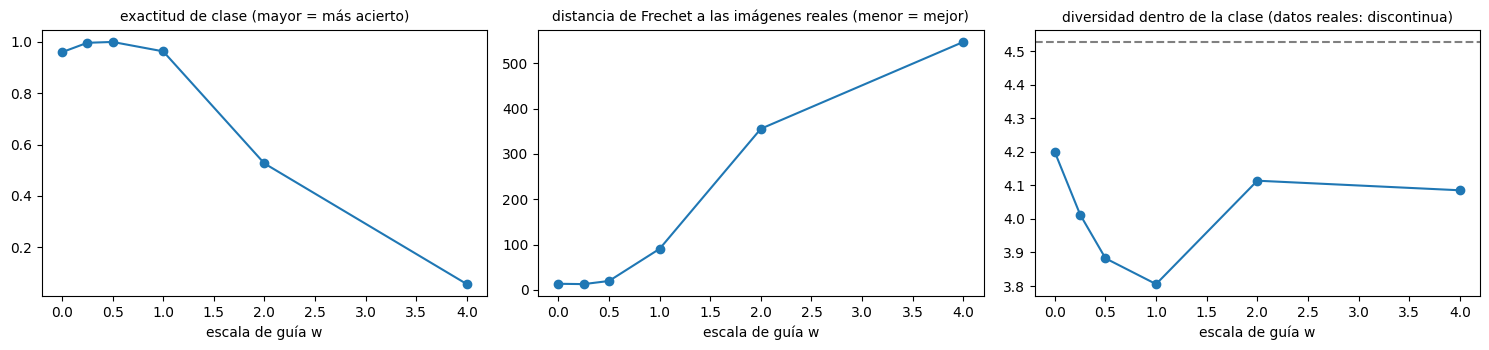

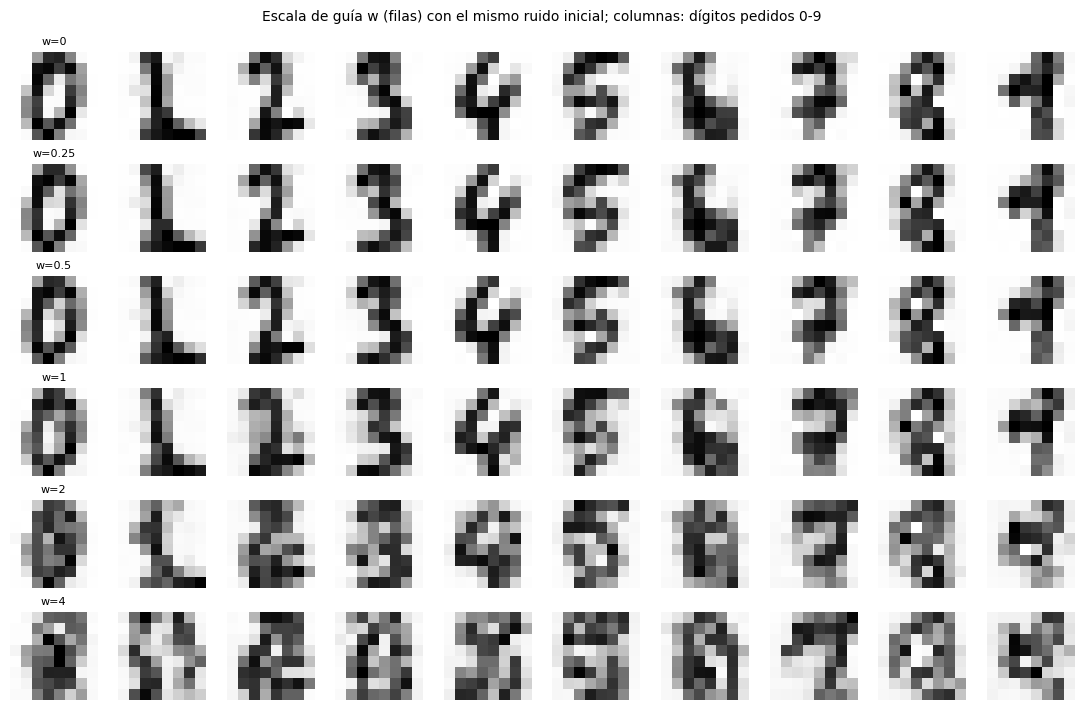

In [6]:
ws = [0, 0.25, 0.5, 1, 2, 4]
gres, gsamples = [], {}
for w in ws:
    xs = ddim_sample(unet, (N, 1, 8, 8), c_eval, w=w, steps=20)
    r = evaluate(xs, c_eval); r["w"] = w; gres.append(r); gsamples[w] = xs
print(f"{'guía w':>10s} {'exactitud':>10s} {'FD':>7s} {'diversidad':>10s}")
for r in gres:
    print(f"{r['w']:10.2f} {r['acc']:10.1%} {r['fd']:7.2f} {r['div']:10.2f}")
print(f"{'real prueba':>10s} {'':>10s} {'':>7s} {diversity(Xte, yte):10.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, key, title in zip(axes, ["acc", "fd", "div"], ["exactitud de clase (mayor = más acierto)", "distancia de Frechet a las imágenes reales (menor = mejor)", "diversidad dentro de la clase (datos reales: discontinua)"]):
    ax.plot(ws, [r[key] for r in gres], "o-"); ax.set_xlabel("escala de guía w"); ax.set_title(title, fontsize=10)
axes[2].axhline(diversity(Xte, yte), color="gray", ls="--")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(ws), 10, figsize=(11, 1.2 * len(ws)))
for r, w in enumerate(ws):
    for k in range(10):
        show(axes[r, k], gsamples[w][k], f"w={w}" if k == 0 else None)
plt.suptitle("Escala de guía w (filas) con el mismo ruido inicial; columnas: dígitos pedidos 0-9", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** Con guía pequeña se cumple el cuadro de los libros: la exactitud sube de 96,0 % (w=0) a 99,7 % (w=0,25) y 100 % (w=0,5), mientras la diversidad baja de 4,20 a 3,88: más acertado y menos variado. La FD es mejor cerca de w=0,25 (13,0) y empeora en 0,5 (19,9): las muestras se vuelven más típicas y menos parecidas a toda la distribución real. Más allá, el juguete **se rompe**: con w=1 la FD salta a 91, con w=2 la exactitud cae a 52,7 % y con w=4 a 5,7 %, y las imágenes (últimas filas de la cuadrícula) pasan a ser textura de alto contraste en lugar de dígitos. La columna de diversidad incluso vuelve a subir con $w$ grande, lo que solo muestra que la basura es "diversa" en distancia de píxeles: buen recordatorio de que ninguna métrica aislada es fiable. La razón es que la estimación guiada $(1+w)\varepsilon_c - w\varepsilon_\varnothing$ extrapola más allá de lo que la red ha visto, y nuestra red es diminuta y solo vio la etiqueta vacía en el 15 % de 1500 pasos de entrenamiento, de modo que la diferencia entre sus dos ramas es sobre todo error, que un $w$ grande amplifica. Los sistemas reales usan escalas de 3 a 8 porque sus redes son grandes y están bien entrenadas, y a menudo añaden trucos como el umbral dinámico para mantener los valores extremos en rango.

## 6. Difusión latente

Hacer difusión sobre cada píxel es un derroche: la mayoría de los píxeles de una foto llevan detalle que el ojo ni siquiera ve. [Rombach et al. (2022)](https://arxiv.org/abs/2112.10752) dividieron el trabajo en dos:

1. un **autoencoder perceptual** (entrenado una vez, sin difusión) que comprime una imagen en un **latente** pequeño y la decodifica casi sin pérdida;
2. un **modelo de difusión que trabaja solo en el espacio latente**, mucho más pequeño (en Stable Diffusion, 512×512×3 píxeles pasan a latentes de 64×64×4, 48 veces menos números), de modo que cada uno de los muchos pasos de eliminación de ruido es mucho más barato.

Generar es: muestrear un latente con difusión y decodificarlo una vez a píxeles. Reproducimos exactamente esa estructura con los dígitos: un pequeño autoencoder variacional (VAE) comprime 64 píxeles en **8 números latentes**, y un MLP (perceptrón multicapa) pequeño como eliminador de ruido, con los mismos embeddings de paso temporal y de clase y el mismo calendario y los mismos muestreadores, hace difusión sobre esos 8 números.

El autoencoder está ligeramente **regularizado** (una pequeña penalización KL (Kullback-Leibler) mantiene los latentes cerca de una gaussiana estándar, que es también lo que hacen Rombach et al., con un término KL o de cuantización vectorial), de modo que el espacio latente no tiene regiones salvajes por las que el modelo de difusión pueda perderse.

In [7]:
LAT = 8
class AE(nn.Module):
    # un VAE pequeño: el codificador da una media y una log-varianza por cada número latente
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.SiLU(), nn.Linear(128, 2 * LAT))
        self.dec = nn.Sequential(nn.Linear(LAT, 128), nn.SiLU(), nn.Linear(128, 64), nn.Tanh())
    def encode(self, x): return self.enc(x).chunk(2, 1)            # (media, log-varianza)
    def decode(self, z): return self.dec(z).view(-1, 1, 8, 8)

torch.manual_seed(0)
BETA_KL = 0.02                                                     # peso del término KL: una regularización ligera, como en la difusión latente
ae = AE(); opt = torch.optim.Adam(ae.parameters(), 2e-3); t0 = time.time()
for it in range(2000):
    b = torch.randint(0, len(Xtr), (128,)); mu, lv = ae.encode(Xtr[b]); z = mu + torch.randn_like(mu) * (0.5 * lv).exp()
    kl = -0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1).mean()
    loss = F.mse_loss(ae.decode(z), Xtr[b]) * 64 + BETA_KL * kl; opt.zero_grad(); loss.backward(); opt.step()
ae.eval()
for q in ae.parameters(): q.requires_grad_(False)
with torch.no_grad():
    Z_tr = ae.encode(Xtr)[0]; z_mean, z_std = Z_tr.mean(0), Z_tr.std(0); rec = ae.decode(ae.encode(Xte)[0])
r_rec = evaluate(rec, yte)
print(f"autoencoder 64 -> {LAT} -> 64 entrenado en {time.time() - t0:.0f}s; MSE de reconstrucción en prueba {F.mse_loss(rec, Xte):.4f}")
print(f"exactitud del clasificador en imágenes de prueba RECONSTRUIDAS: {r_rec['acc']:.1%}  (el techo de cualquier cosa decodificada desde este espacio latente)")

class LatentDenoiser(nn.Module):
    def __init__(self, emb=64, hid=256):
        super().__init__()
        self.emb = emb; self.cls = nn.Embedding(11, emb)
        self.t_mlp = nn.Sequential(nn.Linear(emb, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.net = nn.Sequential(nn.Linear(LAT + emb, hid), nn.SiLU(), nn.Linear(hid, hid), nn.SiLU(), nn.Linear(hid, hid), nn.SiLU(), nn.Linear(hid, LAT))
    def forward(self, z, t, c):
        e = self.t_mlp(timestep_embedding(t, self.emb)) + self.cls(c)
        return self.net(torch.cat([z, e], 1))

Zn = (Z_tr - z_mean) / z_std                                       # estandarizar los latentes para que el calendario de ruido les encaje
lden = LatentDenoiser(); opt = torch.optim.AdamW(lden.parameters(), 2e-3)
LSTEPS = 2500
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=LSTEPS)
gen = torch.Generator().manual_seed(0); t0 = time.time()
for it in range(LSTEPS):
    b = torch.randint(0, len(Zn), (256,), generator=gen)
    z0, c = Zn[b], ytr[b].clone(); c[torch.rand(256, generator=gen) < P_DROP] = NULL
    t = torch.randint(0, T, (256,), generator=gen); eps = torch.randn(z0.shape, generator=gen); a = ab[t][:, None]
    loss = F.mse_loss(lden(a.sqrt() * z0 + (1 - a).sqrt() * eps, t, c), eps)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
lden.eval()
print(f"eliminador de ruido latente: {count_params(lden):,} parámetros (U-Net en píxeles: {count_params(unet):,}), entrenados {LSTEPS} pasos en {time.time() - t0:.0f}s")

autoencoder 64 -> 8 -> 64 entrenado en 9s; MSE de reconstrucción en prueba 0.0444
exactitud del clasificador en imágenes de prueba RECONSTRUIDAS: 96.2%  (el techo de cualquier cosa decodificada desde este espacio latente)


eliminador de ruido latente: 161,352 parámetros (U-Net en píxeles: 150,529), entrenados 2500 pasos en 33s


modelo                              w  exactitud      FD diversidad   s/300 imág.


difusión en píxeles (U-Net)       0.0      96.0%   13.70       4.20          1.57
difusión latente (MLP + AE)       0.0      97.7%   15.85       3.91          0.13


difusión en píxeles (U-Net)       2.0      52.7%  355.45       4.11          2.99
difusión latente (MLP + AE)       2.0      92.7%   34.77       3.95          0.15
reconstrucciones del autoencoder    -      96.2%    5.39       3.93


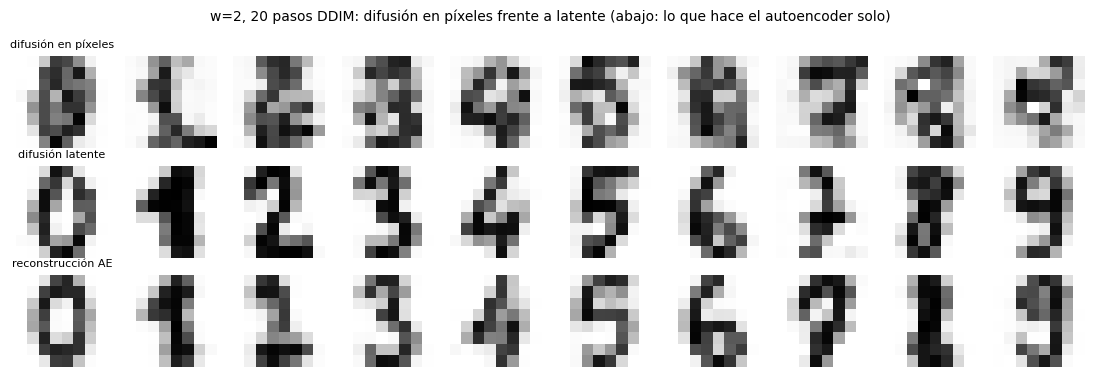

In [8]:
@torch.no_grad()
def ddim_latent(w, steps=20, eta=0.0, seed=0):
    # el mismo muestreador, pero la "imagen" es un latente de 8 números; se decodifica una vez al final.
    # Como el recorte a [-1, 1] en píxeles, recortamos el latente limpio predicho a +-3 desviaciones típicas (sin él, las primeras
    # estimaciones erróneas de un latente sin límites pueden dispararse y el decodificador recibe valores que nunca vio)
    g = torch.Generator().manual_seed(seed); z = torch.randn((N, LAT), generator=g)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, t in enumerate(ts):
        e = eps_hat(lden, z, t, c_eval, w)
        a = ab[t]; ap = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        z0 = ((z - (1 - a).sqrt() * e) / a.sqrt()).clamp(-3, 3)
        z = ap.sqrt() * z0 + (1 - ap).sqrt() * e
    return ae.decode(z * z_std + z_mean)

lat_res = []
print(f"{'modelo':32s} {'w':>4s} {'exactitud':>10s} {'FD':>7s} {'diversidad':>10s} {'s/300 imág.':>13s}")
for w in (0, 2):
    t0 = time.time(); xs = ddim_latent(w); dt_lat = time.time() - t0
    r = evaluate(xs, c_eval); lat_res.append(r)
    t0 = time.time(); xp = ddim_sample(unet, (N, 1, 8, 8), c_eval, w=w, steps=20); dt_pix = time.time() - t0
    rp = evaluate(xp, c_eval)
    print(f"{'difusión en píxeles (U-Net)':32s} {w:4.1f} {rp['acc']:10.1%} {rp['fd']:7.2f} {rp['div']:10.2f} {dt_pix:13.2f}")
    print(f"{'difusión latente (MLP + AE)':32s} {w:4.1f} {r['acc']:10.1%} {r['fd']:7.2f} {r['div']:10.2f} {dt_lat:13.2f}")
    if w == 2: xl2, xp2 = xs, xp
print(f"{'reconstrucciones del autoencoder':32s} {'-':>4s} {r_rec['acc']:10.1%} {r_rec['fd']:7.2f} {r_rec['div']:10.2f}")

fig, axes = plt.subplots(3, 10, figsize=(11, 3.8))
for k in range(10):
    show(axes[0, k], xp2[k], "difusión en píxeles" if k == 0 else None)
    show(axes[1, k], xl2[k], "difusión latente" if k == 0 else None)
    show(axes[2, k], rec[yte == k][0], "reconstrucción AE" if k == 0 else None)
plt.suptitle("w=2, 20 pasos DDIM: difusión en píxeles frente a latente (abajo: lo que hace el autoencoder solo)", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** El autoencoder comprime 64 píxeles en 8 números y sus reconstrucciones aún se reconocen el 96,2 % de las veces (FD 5,4): es el **techo** de calidad de todo lo que se decodifique desde este espacio latente. La difusión en ese espacio sin guía alcanza 97,7 % de exactitud de clase y FD 15,9, cerca del modelo en píxeles (96,0 %, FD 13,7), algo peor en FD, como cabe esperar de un techo más el error propio del eliminador de ruido. El ahorro está en el coste del muestreo: aproximadamente 0,1 a 0,2 s frente a 1,9 a 3,9 s para 300 imágenes con 20 pasos (unas 20 veces más rápido; los tiempos exactos dependen de la carga de la máquina, mira la tabla de arriba), aunque los dos eliminadores de ruido tienen un número de parámetros parecido (161 mil y 150 mil), porque cada paso latente maneja 8 números con un MLP pequeño en lugar de una imagen de 64 píxeles con convoluciones. Con guía w=2 el modelo latente conserva el 92,7 % de exactitud donde el de píxeles colapsó (52,7 %); no hay que leer demasiado en eso, ya que el muestreador latente además recorta sus predicciones y el fallo del modelo en píxeles viene de la rama de etiqueta vacía débil comentada arriba. Dos salvedades honestas: una versión anterior de esta celda sin el recorte del latente predicho puntuaba solo un 67 a 69 % de exactitud (valores desbocados que el decodificador nunca había visto), y una imagen pequeña de dígitos no gana calidad real con un espacio latente; lo que importa aquí es la estructura, cuyo beneficio en sistemas reales (48 veces menos números) es grande.

## 7. Cómo encaja un sistema de texto a imagen

Un sistema que convierte "una bicicleta roja apoyada en un muro de ladrillo" en una imagen es el conjunto de piezas de este notebook más una forma de *leer la frase*:

```
 "una bicicleta roja ..."                              ruido latente aleatorio (p. ej. 64x64x4)
        |                                                         |
  CODIFICADOR DE TEXTO (transformer, notebook 09 de Redes Neuronales 1001)                 v
  un vector por token                           +-----------------------------------+
        |   claves / valores                    |  ELIMINADOR DE RUIDO, 20-50 pasos |
        +-------- atención cruzada -----------> |  U-Net (conv + atención)          |
        |         en cada bloque                |  o transformer de difusión (DiT)  |
        |   (y, para la guía, una pasada        |  + embedding del paso temporal    |
        |    con un prompt VACIO)               +-----------------------------------+
                                                                  |  latente limpio
                                                                  v
                                                       DECODIFICADOR VAE (una vez) -> píxeles
```

| Componente | Función | En nuestro juguete | En un sistema real |
|---|---|---|---|
| **Codificador de texto** | convierte el prompt en una secuencia de vectores con significado | la etiqueta del dígito, uno de 11 embeddings | un transformer congelado (por ejemplo un codificador de texto CLIP (preentrenamiento contrastivo lenguaje-imagen) o un modelo de lenguaje T5), entrenado con enormes corpus de texto o de pares imagen-texto |
| **Condicionamiento por atención cruzada** | deja que cada posición de la imagen mire las palabras que le importan: las consultas vienen de las características de la imagen, las claves y valores de los vectores de texto (notebook 09 de Redes Neuronales 1001) | el embedding de la etiqueta se *suma* a cada bloque | capas de atención dentro de cada bloque de la U-Net |
| **Difusión latente** | eliminación de ruido barata en un espacio comprimido ([Rombach et al.](https://arxiv.org/abs/2112.10752)) | de 64 píxeles a 8 números | unas 8 veces menos por lado, 48 veces menos valores en una imagen en color |
| **Eliminador de ruido** | predice el ruido | U-Net de 150 mil parámetros | U-Net de unos 1000 millones de parámetros, o un **transformer de difusión** ([Peebles y Xie, 2023](https://arxiv.org/abs/2212.09748)) que trata parches latentes como tokens |
| **Guía sin clasificador** | fidelidad al prompt frente a variedad | $w$ de 0 a 4, sección 5 | típicamente una escala de 3 a 8, con el prompt vacío como rama incondicional |
| **Decodificador** | de latente a píxeles, una vez | el decodificador del autoencoder | un decodificador VAE convolucional |

### Opcional: un modelo real (pequeño) de texto a imagen preentrenado

El juguete desde cero de arriba es el núcleo conceptual; la siguiente celda muestra la tubería real con un punto de control abierto pequeño, **[nota-ai/bk-sdm-tiny](https://huggingface.co/nota-ai/bk-sdm-tiny)** ([Kim et al., 2023](https://arxiv.org/abs/2305.15798)), una versión comprimida de Stable Diffusion v1.4 con una U-Net más pequeña (unos 0,33 mil millones de parámetros en la U-Net). Licencia: **CreativeML OpenRAIL-M** (restricciones de uso, lee la ficha del modelo). La celda descarga unos 1,1 GB una vez (en caché de Hugging Face, en `~/.cache/huggingface`) y necesita `pip install diffusers`; si el paquete o la red no están disponibles, la celda imprime el motivo y no hace nada. Generamos a 256×256 con 12 pasos de un resolvedor rápido, así que la calidad queda muy por debajo del mejor resultado del modelo a 512×512, pero los cuatro ingredientes de arriba están presentes y visibles: el codificador de texto, la atención cruzada, la difusión latente y el decodificador VAE. Cargamos solo los pesos que usamos (sin comprobador de seguridad, para ahorrar 600 MB): para cualquier uso fuera de esta demo de clase, mantén el comprobador y lee las restricciones de uso.

In [9]:
import importlib.util
PRETRAINED_OK = False
if importlib.util.find_spec("diffusers") is None:
    print("diffusers no está instalado (pip install diffusers): se omite la demo opcional preentrenada.")
else:
    try:
        os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
        import transformers
        from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
        from diffusers.utils import logging as diffusers_logging
        transformers.logging.disable_progress_bar(); diffusers_logging.disable_progress_bar()    # mantener corta la salida del notebook
        t0 = time.time()
        pipe = StableDiffusionPipeline.from_pretrained("nota-ai/bk-sdm-tiny", torch_dtype=torch.float32, variant="fp16",
                                                        use_safetensors=True, safety_checker=None, requires_safety_checker=False)
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
        pipe.set_progress_bar_config(disable=True)
        print(f"cargado en {time.time() - t0:.0f}s;  U-Net {count_params(pipe.unet) / 1e6:.0f}M, codificador de texto {count_params(pipe.text_encoder) / 1e6:.0f}M, VAE {count_params(pipe.vae) / 1e6:.0f}M parámetros")
        PRETRAINED_OK = True
    except Exception as err:                                      # sin conexión, modelo retirado, versiones incompatibles...
        print("no se pudo cargar el modelo preentrenado:", type(err).__name__, str(err)[:200])

cargado en 4s;  U-Net 323M, codificador de texto 123M, VAE 84M parámetros


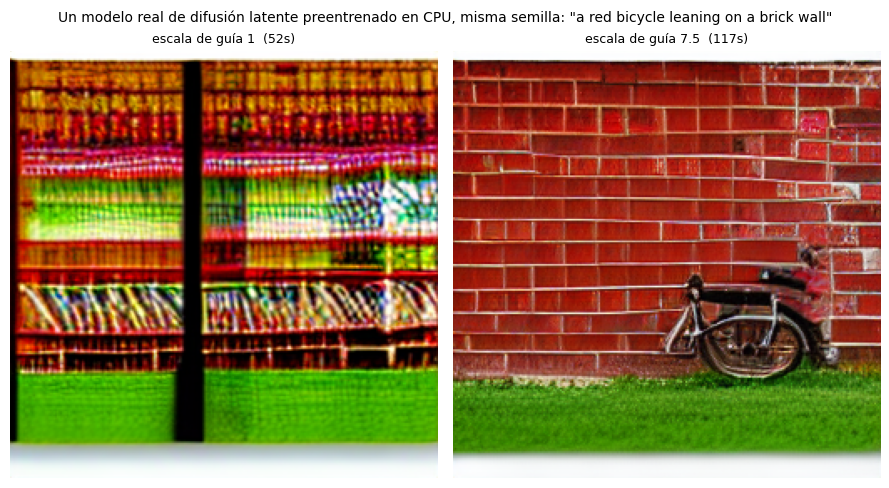

In [10]:
if PRETRAINED_OK:
    prompt = "a red bicycle leaning on a brick wall"
    scales = [1.0, 7.5]
    fig, axes = plt.subplots(1, len(scales), figsize=(9, 5))
    for k, scale in enumerate(scales):
        t0 = time.time()
        img = pipe(prompt, height=256, width=256, num_inference_steps=12, guidance_scale=scale,
                   generator=torch.Generator().manual_seed(7)).images[0]
        axes[k].imshow(img); axes[k].axis("off")
        axes[k].set_title(f"escala de guía {scale:g}  ({time.time() - t0:.0f}s)", fontsize=9)
    plt.suptitle(f'Un modelo real de difusión latente preentrenado en CPU, misma semilla: "{prompt}"', fontsize=10)
    plt.tight_layout(); plt.show()
else:
    print("(omitido) El código de esta celda llama a pipe(prompt, height=256, width=256, num_inference_steps=12, guidance_scale=s) para s en 1, 7.5.")

**Lectura.** Con la misma semilla y una escala de guía de 1 (el prompt apenas se impone) la muestra de 12 pasos es ruido de color saturado y rayado en rojo y verde: algo de "rojo" y algo de "césped" pero ninguna escena. Con una escala de 7,5 el mismo ruido inicial se convierte en un muro de ladrillo reconocible, césped y un objeto que se lee como una bicicleta en su base (pequeña y poco convincente a 256×256 con un modelo comprimido y 12 pasos). Es la guía sin clasificador haciendo en un sistema real lo que la sección 5 midió en el juguete: el prompt se obedece mucho mejor, a costa de variedad, y una escala de guía de 1 frente a 7,5 es la diferencia entre ruido y una imagen. Cada imagen tardó de uno a tres minutos en la CPU de un portátil ocupado (el tiempo en los títulos es de reloj de pared para 12 pasos de una U-Net de 0,32 mil millones de parámetros más dos codificaciones de texto, porque la guía ejecuta la red dos veces); una muestra completa de 512×512 con 25 a 50 pasos de un modelo mayor es lo que hace de las GPU la opción normal.

## 8. Qué le falta a este juguete, y seguridad y ética

**Dónde difiere el juguete de los sistemas reales.** Nuestras imágenes tienen 64 píxeles, un canal y diez clases; los sistemas reales generan millones de píxeles en color a partir de texto libre, con eliminadores de ruido de unos mil millones de parámetros entrenados durante semanas en miles de GPU (unidades de procesamiento gráfico) con miles de millones de pares imagen-texto. Nuestra "FD" usa un clasificador diminuto en lugar de la red Inception estándar, nuestro latente de 8 números no es un autoencoder perceptual entrenado con pérdidas antagónicas y perceptuales, y nuestro condicionamiento es un embedding de etiqueta, no lenguaje. Lo que sí se transfiere es el mecanismo: entrenamiento por predicción de ruido, condicionamiento por paso temporal, muestreo rápido tipo DDIM, guía y difusión en el espacio latente. Lo que **no** se transfiere es cualquier afirmación sobre calidad absoluta, ni los números de las tablas de arriba.

**Seguridad y ética.** Los generadores de imágenes son potentes y los riesgos son concretos:

* **Derechos de autor y consentimiento.** Los modelos se entrenan con colecciones enormes extraídas de la web que incluyen obras con derechos de autor y fotografías personales, a menudo sin que sus autores lo sepan. El estatus legal difiere entre países y se está decidiendo en los tribunales; los modelos a veces pueden reproducir casi-copias de imágenes de entrenamiento. Licencias como OpenRAIL-M añaden *restricciones de uso* a los pesos. Si entrenas o ajustas un modelo, documenta la procedencia de tus datos.
* **Deepfakes y desinformación.** Imágenes falsas fotorrealistas de personas reales, o de sucesos que nunca ocurrieron, pueden usarse para fraude, acoso, imágenes íntimas no consentidas y manipulación política. No las generes ni las compartas; denúncialas cuando las encuentres.
* **Sesgo.** Los generadores reproducen y amplifican los estereotipos de sus datos (quién aparece como "médico" o "delincuente"). Prueba prompts con distintos grupos antes de desplegar.
* **Procedencia y marcas de agua.** Existen dos defensas complementarias: las **marcas de agua invisibles** incrustadas en los píxeles o en el ruido de muestreo por el generador (ayudan a detectar imágenes hechas por máquina, pero pueden debilitarse con recortes, recodificación o ataques deliberados) y los **metadatos de procedencia firmados**, como el estándar abierto [C2PA](https://c2pa.org/) (registran criptográficamente cómo se hizo un archivo, pero se pierden si se eliminan los metadatos). Ninguna es una solución completa, por lo que también se usan filtros de seguridad sobre el prompt y la salida, términos de uso y moderación en las plataformas. El mismo mecanismo de guía sin clasificador se usa para *alejarse* de conceptos no deseados con prompts negativos.
* **Coste ambiental y económico.** Entrenar es caro; generar es barato por imagen pero enorme en conjunto, que es la razón práctica por la que importan los muestreadores rápidos como DDIM.

## Ideas clave

* Un modelo de difusión es una **regresión de ruido**: se añade ruido a una imagen con la forma cerrada $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\varepsilon$, se predice $\varepsilon$ con una red a la que se le dice $t$ y se minimiza un error cuadrático medio. La estabilidad de esa pérdida es la razón principal por la que la difusión desplazó a las GAN.
* El **calendario de ruido** importa: uno lineal gasta muchos pasos en ruido casi puro; el coseno mantiene señal más tiempo.
* **DDIM** reutiliza la misma red entrenada con menos pasos deterministas; el precio medido de la velocidad está en la tabla de la sección 4.
* La **guía sin clasificador** cambia diversidad por fidelidad con un solo mando y sin modelo extra; mira las curvas medidas de la sección 5.
* La **difusión latente** abarata cada paso eliminando ruido de un código comprimido; su calidad queda limitada por el autoencoder (sección 6).
* Un sistema de texto a imagen son estas piezas más un **codificador de texto y atención cruzada**; el punto de control real de la sección 7 los muestra funcionando juntos.
* Generar imágenes trae problemas reales de **derechos de autor, deepfakes, sesgo y procedencia** que la ingeniería sola no resuelve.

## Ejercicios

1. Entrena el eliminador de ruido con el calendario **lineal** en lugar del coseno (cambia `SCH["cosine"]` en la celda de entrenamiento y en los muestreadores) y compara la FD final con 20 pasos DDIM.
2. Entrena 500 pasos en lugar de 1500 y repite el barrido de pasos de DDIM. ¿Sufre DDIM con pocos pasos más o menos cuando la red está poco entrenada?
3. Predice $x_0$ en lugar de $\varepsilon$ (cambia el objetivo de la pérdida y la fórmula del muestreador). ¿Qué es más fácil de aprender con $t$ grande, y con $t$ pequeño?
4. Dibuja el barrido de guía para DDIM con 5 pasos en lugar de 20. ¿Interactúa la guía con el número de pasos?
5. Prueba tamaños latentes de 2, 4 y 16. ¿Cómo cambia el techo del autoencoder (la exactitud del clasificador sobre las reconstrucciones) y cómo lo sigue el resultado de la difusión latente?
6. Interpola entre dos ruidos fijos con el muestreador DDIM determinista ($\eta=0$) y mira las imágenes intermedias. ¿Por qué es imposible con DDPM?
7. Busca la ficha del modelo enlazada en la sección 7 y enumera tres limitaciones o restricciones que declara. ¿Cómo comprobarías tu propio uso frente a ellas?

## Referencias

Todos los enlaces se comprobaron al escribir este notebook.

* Ho, Jain y Abbeel (2020). *Denoising Diffusion Probabilistic Models* (DDPM). [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)
* Song, Meng y Ermon (2021). *Denoising Diffusion Implicit Models* (DDIM). [arXiv:2010.02502](https://arxiv.org/abs/2010.02502)
* Nichol y Dhariwal (2021). *Improved Denoising Diffusion Probabilistic Models* (calendario coseno). [arXiv:2102.09672](https://arxiv.org/abs/2102.09672)
* Ho y Salimans (2022). *Classifier-Free Diffusion Guidance*. [arXiv:2207.12598](https://arxiv.org/abs/2207.12598)
* Rombach, Blattmann, Lorenz, Esser y Ommer (2022). *High-Resolution Image Synthesis with Latent Diffusion Models*. [arXiv:2112.10752](https://arxiv.org/abs/2112.10752)
* Song, Sohl-Dickstein, Kingma, Kumar, Ermon y Poole (2021). *Score-Based Generative Modeling through Stochastic Differential Equations*. [arXiv:2011.13456](https://arxiv.org/abs/2011.13456)
* Peebles y Xie (2023). *Scalable Diffusion Models with Transformers* (DiT). [arXiv:2212.09748](https://arxiv.org/abs/2212.09748)
* Sohl-Dickstein, Weiss, Maheswaranathan y Ganguli (2015). *Deep Unsupervised Learning using Nonequilibrium Thermodynamics*. [arXiv:1503.03585](https://arxiv.org/abs/1503.03585)
* Kingma y Welling (2014). *Auto-Encoding Variational Bayes* (VAE). [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)
* Goodfellow et al. (2014). *Generative Adversarial Networks*. [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)
* Kim et al. (2023). *BK-SDM: A Lightweight, Fast, and Cheap Version of Stable Diffusion*. [arXiv:2305.15798](https://arxiv.org/abs/2305.15798); ficha del modelo [nota-ai/bk-sdm-tiny](https://huggingface.co/nota-ai/bk-sdm-tiny)
* Alpaydin y Kaynak. *Optical Recognition of Handwritten Digits* (UCI), CC BY 4.0. [archive.ics.uci.edu](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits)
* C2PA, Coalición para la Procedencia y Autenticidad de los Contenidos. [c2pa.org](https://c2pa.org/)